# 01 - Exploratory data analysis

What the CERT r4.2 data looks like, how the label is defined, how imbalanced it is, and what the graph and split look like. Reusable logic lives in `src/itgnn/`; this notebook only tells the story. Every number below is computed in code.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from itgnn.data import load_config, load_log, load_labels, subsample_users, make_split
from itgnn.graph import FEATURE_COLS, user_features, build_graph

# Work from the repo root whether Jupyter starts in notebooks/ or at the root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
cfg = load_config(ROOT / "configs" / "config.yaml")
RAW = ROOT / cfg["raw_dir"]
CACHE = ROOT / "data" / "processed"  # parquet cache: file.csv is slow to parse

sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.3f}".format
logs = {n: load_log(RAW, n, cache_dir=CACHE) for n in ["logon", "device", "file"]}
logon, device, file = logs["logon"], logs["device"], logs["file"]
labels = load_labels(RAW)
all_users = sorted(logon["user"].unique())

## 1. Dataset overview

Before modelling anything we check the basics: how big each log is, what types the columns have, the time span, how many users and PCs exist, which activity types occur, and whether there are gaps or duplicates. Surprises here (missing values, duplicate events) would silently distort features later. Note `load_log` keeps only the columns we need, so the big `content` text column of `file.csv` is dropped.

In [2]:
summary = pd.DataFrame({
    "rows": {n: len(d) for n, d in logs.items()},
    "columns": {n: ", ".join(d.columns) for n, d in logs.items()},
    "first event": {n: d["date"].min() for n, d in logs.items()},
    "last event": {n: d["date"].max() for n, d in logs.items()},
    "unique users": {n: d["user"].nunique() for n, d in logs.items()},
    "unique PCs": {n: d["pc"].nunique() for n, d in logs.items()},
    "missing values": {n: int(d.isna().sum().sum()) for n, d in logs.items()},
    "identical slimmed rows*": {n: int(d.duplicated().sum()) for n, d in logs.items()},
})
display(summary)
print('* rows identical on the slimmed columns only (event id dropped), NOT a true duplicate count; see the next cell.')
for n, d in logs.items():
    print(f"\n{n} dtypes"); print(d.dtypes.to_string())
for n in ["logon", "device"]:
    print(f"\n{n} activity types"); print(logs[n]["activity"].value_counts().to_string())
print("\nusers in all three logs:", len(set(logon.user) & set(device.user) & set(file.user)), "of", len(all_users))

,rows,columns,first event,last event,unique users,unique PCs,missing values,identical slimmed rows*
logon,854859,"date, user, pc, activity",2010-01-02 06:49:00,2011-05-17 06:43:35,1000,1003,0,0
device,405380,"date, user, pc, activity",2010-01-02 07:21:06,2011-05-16 23:22:34,265,971,0,6
file,445581,"date, user, pc",2010-01-02 07:23:14,2011-05-16 23:22:34,264,956,0,6463


* rows identical on the slimmed columns only (event id dropped), NOT a true duplicate count; see the next cell.

logon dtypes
date        datetime64[us]
user                   str
pc                     str
activity               str

device dtypes
date        datetime64[us]
user                   str
pc                     str
activity               str

file dtypes
date    datetime64[us]
user               str
pc                 str

logon activity types
activity
Logon     470591
Logoff    384268

device activity types
activity
Connect       203339
Disconnect    202041



users in all three logs: 264 of 1000


In [3]:
# True duplicate check: re-read the raw CSVs WITH the event id column (not kept by load_log).
key = {"logon": ["date", "user", "pc", "activity"], "device": ["date", "user", "pc", "activity"],
       "file": ["date", "user", "pc", "filename"]}
dup = {}
for n, k in key.items():
    raw = pd.read_csv(RAW / f"{n}.csv", usecols=["id"] + k)
    dup[n] = {
        "rows": len(raw),
        "duplicate event ids": int(raw["id"].duplicated().sum()),
        "fully identical rows (incl. id)": int(raw.duplicated().sum()),
        "same event key, ignoring id": int(raw.duplicated(subset=k).sum()),
        "event key": "/".join(k),
    }
display(pd.DataFrame(dup).T)
print('Event ids are unique; identical slimmed rows are therefore distinct events (e.g. several files copied in the same second) unless the event key also repeats.')

,rows,duplicate event ids,fully identical rows (incl. id),"same event key, ignoring id",event key
logon,854859,0,0,0,date/user/pc/activity
device,405380,0,0,6,date/user/pc/activity
file,445581,0,0,0,date/user/pc/filename


Event ids are unique; identical slimmed rows are therefore distinct events (e.g. several files copied in the same second) unless the event key also repeats.


## 2. The label

The dataset has no per-event label. Following the CERT answer key, a user is **malicious** if they appear in `answers/insiders.csv` for release 4.2; everyone else is **normal**. This is a user-level label, which is why we classify users rather than events. The `scenario` column says which of the CERT attack stories the insider follows.

In [4]:
insiders = pd.read_csv(RAW / "answers" / "insiders.csv")
insiders = insiders[insiders["dataset"].astype(str) == "4.2"]
print("malicious users (release 4.2):", len(insiders), "| unique:", insiders["user"].nunique())
print("all malicious users present in logon log:", set(insiders["user"]) <= set(all_users))
scen = insiders.groupby("scenario").size().rename("n_users").to_frame()
display(scen)
display(insiders[["scenario", "user", "start", "end"]].head())

malicious users (release 4.2): 70 | unique: 70
all malicious users present in logon log: True


,n_users
scenario,
1,30
2,30
3,10


,scenario,user,start,end
8,1,AAM0658,10/23/2010 01:34:19,10/29/2010 05:23:28
9,1,AJR0932,09/10/2010 19:12:01,09/18/2010 02:02:51
10,1,BDV0168,07/30/2010 19:56:44,08/10/2010 05:16:41
11,1,BIH0745,07/13/2010 20:15:23,07/13/2010 21:20:44
12,1,BLS0678,09/21/2010 01:16:22,09/30/2010 04:48:19


## 3. Class imbalance

If malicious users are rare, a model that calls everyone normal looks very accurate while catching nothing. We quantify the imbalance to see how bad that is, which justifies PR-AUC, precision and recall instead of accuracy.

,users,percent
normal,930,93.000
malicious,70,7.000


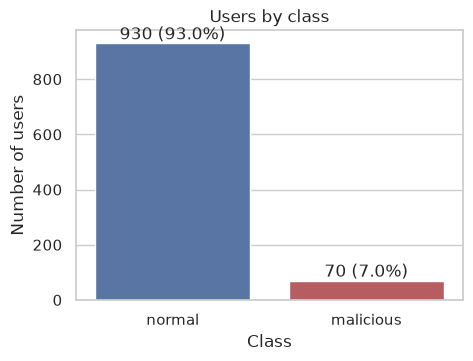

A model that predicts 'normal' for everyone gets 93.0% accuracy and finds 0 insiders.


In [5]:
y_all = pd.Series({u: int(u in labels) for u in all_users})
counts = y_all.map({0: "normal", 1: "malicious"}).value_counts()
pct = (counts / counts.sum() * 100).round(2)
display(pd.DataFrame({"users": counts, "percent": pct}))
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette={"normal": "#4c72b0", "malicious": "#c44e52"}, ax=ax)
for i, (c, p) in enumerate(zip(counts.values, pct.values)):
    ax.text(i, c, f"{c} ({p}%)", ha="center", va="bottom")
ax.set(title="Users by class", xlabel="Class", ylabel="Number of users")
plt.show()
print(f"A model that predicts 'normal' for everyone gets {pct['normal']:.1f}% accuracy and finds 0 insiders.")

**Why accuracy misleads:** with so few malicious users, predicting "normal" for everyone already scores a very high accuracy (number printed above) while detecting nothing. Accuracy rewards the majority class; PR-AUC, precision and recall focus on the rare class we care about.

## 4. Features

The baseline and the GNN node inputs use five simple per-user activity counts from `itgnn.graph.user_features`. Here we compute them for all users and look at their summary statistics.

In [6]:
defs = pd.DataFrame({"definition": {
    "n_logon": "Number of Logon events by the user",
    "n_after_hours": "Logon events outside 07:00-18:59",
    "n_pcs": "Number of distinct PCs the user logged on to",
    "n_device": "Number of removable-device events (connect + disconnect)",
    "n_file": "Number of file-copy events",
}}).loc[FEATURE_COLS]
display(defs)
feats = user_features(logon, device, file, all_users)
feats["malicious"] = y_all.reindex(feats.index).astype(bool)
display(feats[FEATURE_COLS].describe().T)

,definition
n_logon,Number of Logon events by the user
n_after_hours,Logon events outside 07:00-18:59
n_pcs,Number of distinct PCs the user logged on to
n_device,Number of removable-device events (connect + d...
n_file,Number of file-copy events


,count,mean,std,min,25%,50%,75%,max
n_logon,"1,000.000",470.591,250.130,29.000,346.000,346.000,620.000,"1,777.000"
n_after_hours,"1,000.000",31.721,134.847,0.000,0.000,0.000,0.000,950.000
n_pcs,"1,000.000",24.271,109.520,1.000,1.000,1.000,2.000,720.000
n_device,"1,000.000",405.380,"1,234.482",0.000,0.000,0.000,14.000,"8,502.000"
n_file,"1,000.000",445.581,"1,461.942",0.000,0.000,0.000,10.250,"11,627.000"


## 5. Malicious vs normal

The key question: do malicious users look different on these features? We compare distributions per class (log scale where values span orders of magnitude), the share of logons that happen after hours, and how correlated the features are with each other and with the label.

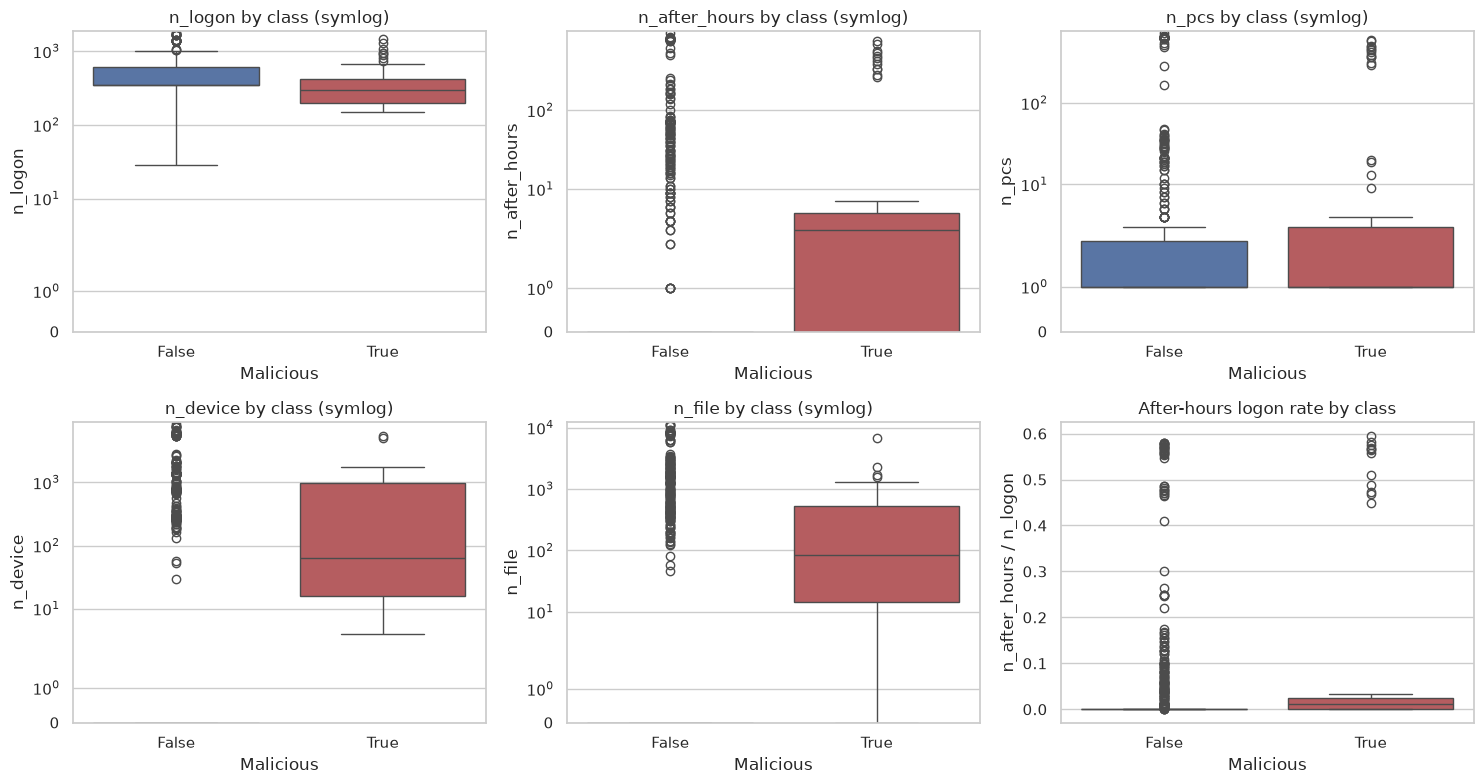

malicious,normal median,malicious median
n_logon,346.000,294.000
n_after_hours,0.000,3.000
n_pcs,1.000,1.000
n_device,0.000,63.000
n_file,0.000,85.500
after_hours_rate,0.000,0.011


In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, FEATURE_COLS):
    sns.boxplot(data=feats, x="malicious", y=col, hue="malicious", palette={False: "#4c72b0", True: "#c44e52"}, legend=False, ax=ax)
    ax.set_yscale("symlog"); ax.set_ylim(bottom=0)
    ax.set(title=f"{col} by class (symlog)", xlabel="Malicious", ylabel=col)
ax = axes.flat[-1]
feats["after_hours_rate"] = feats["n_after_hours"] / feats["n_logon"].replace(0, np.nan)
sns.boxplot(data=feats, x="malicious", y="after_hours_rate", hue="malicious", palette={False: "#4c72b0", True: "#c44e52"}, legend=False, ax=ax)
ax.set(title="After-hours logon rate by class", xlabel="Malicious", ylabel="n_after_hours / n_logon")
plt.tight_layout(); plt.show()
display(feats.groupby("malicious")[FEATURE_COLS + ["after_hours_rate"]].median().T.rename(columns={False: "normal median", True: "malicious median"}))

% of users with at least one event of each kind


,n_after_hours,n_device,n_file
normal,15.900,21.000,21.000
malicious,60.000,100.000,98.600


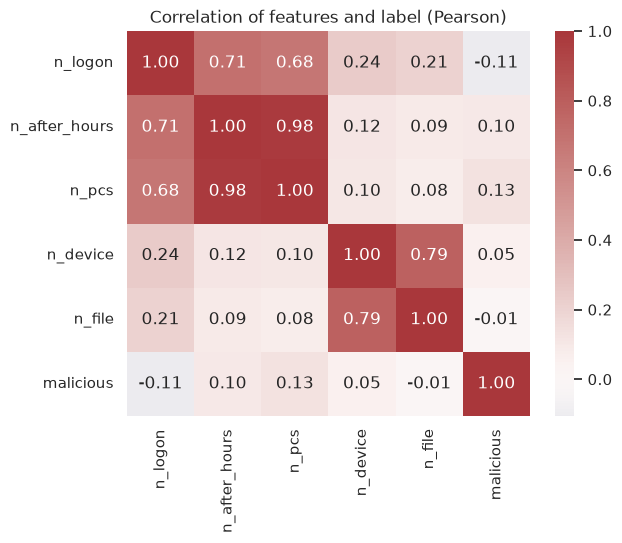

In [8]:
share = (feats[["n_after_hours", "n_device", "n_file"]] > 0).groupby(feats["malicious"]).mean().mul(100)
share.index = ["normal", "malicious"]
print("% of users with at least one event of each kind"); display(share.round(1))
corr = feats[FEATURE_COLS + ["malicious"]].astype(float).corr()
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Correlation of features and label (Pearson)")
plt.show()

## 6. Activity over time

We check that the logs cover the same period, whether volume is steady (weekday/weekend rhythm, holidays, spikes), and whether a handful of users produce most of the events. Heavy concentration would mean a few users dominate the graph and feature scale.

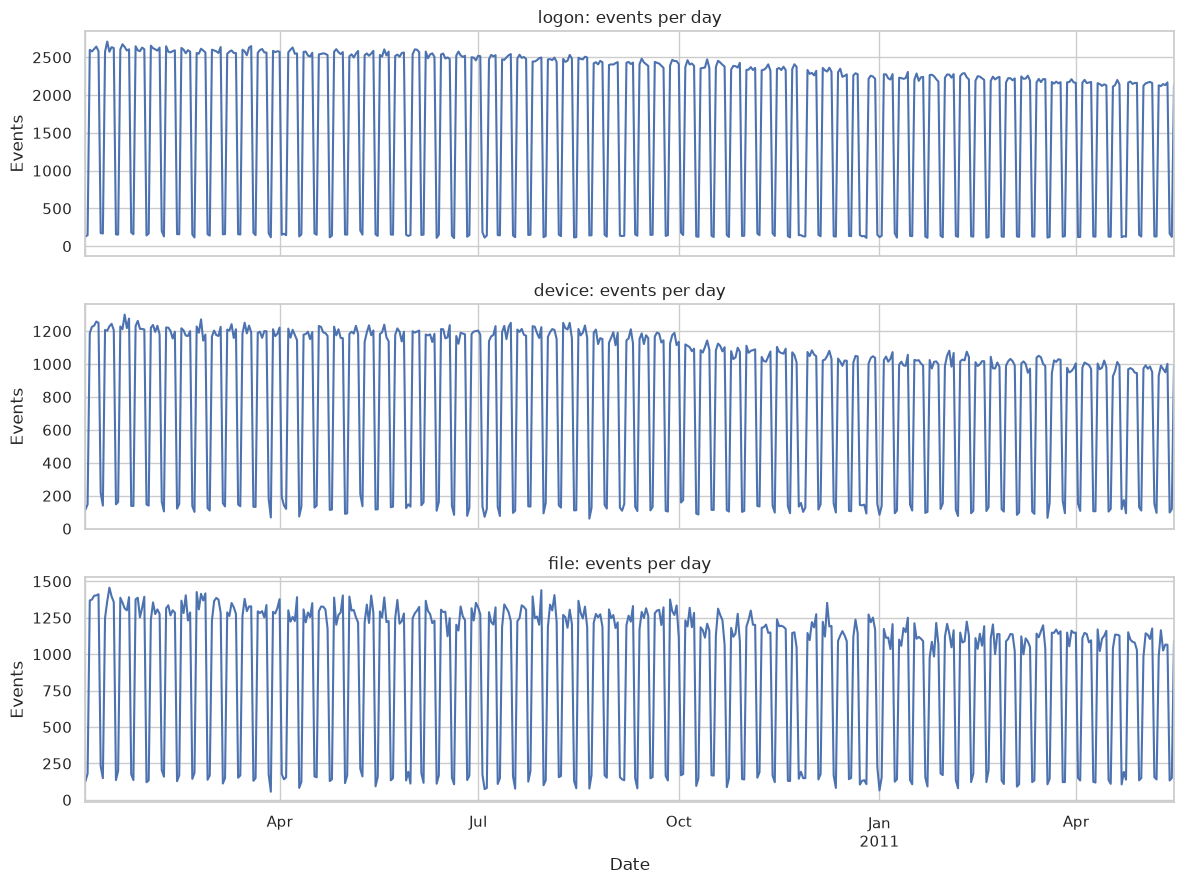

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, (n, d) in zip(axes, logs.items()):
    d.set_index("date").resample("D").size().plot(ax=ax)
    ax.set(title=f"{n}: events per day", xlabel="Date", ylabel="Events")
plt.tight_layout(); plt.show()

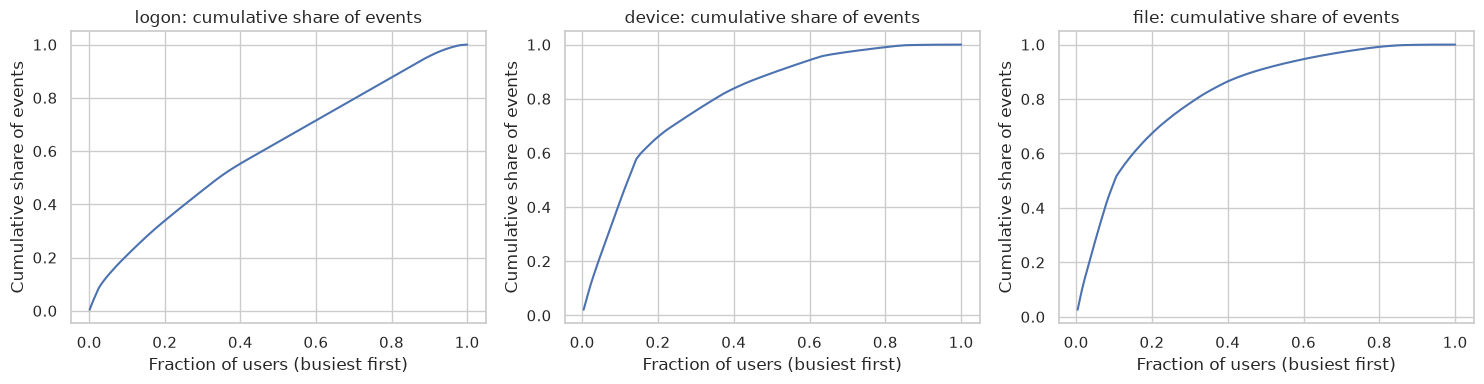

,top 10% users' share of events,median events/user,max events/user
logon,0.209,692.000,"3,470.000"
device,0.415,779.000,"8,502.000"
file,0.490,647.000,"11,627.000"


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
rows = {}
for ax, (n, d) in zip(axes, logs.items()):
    per_user = d["user"].value_counts()
    share = per_user.cumsum() / per_user.sum()
    top10 = share.iloc[max(int(len(per_user) * 0.1) - 1, 0)]
    rows[n] = {"top 10% users' share of events": top10, "median events/user": per_user.median(), "max events/user": per_user.max()}
    ax.plot(np.arange(1, len(share) + 1) / len(share), share.values)
    ax.set(title=f"{n}: cumulative share of events", xlabel="Fraction of users (busiest first)", ylabel="Cumulative share of events")
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).T)

## 7. The graph

The GNN sees a bipartite graph: user nodes and PC nodes, joined by an edge when a user logged on to a PC. We build it with `build_graph` and look at its size, density and degrees. Degree is how many distinct PCs a user touches (or how many distinct users a PC has). Users who roam across many PCs may stand out.

/home/nothing/insider-threat-gnn/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


user nodes: 1000 | PC nodes: 1003 | undirected edges: 24271
bipartite density: 0.0242


,user degree,PC degree
count,"1,000.000","1,003.000"
mean,24.271,24.198
std,109.520,10.655
min,1.000,1.000
25%,1.000,22.000
50%,1.000,25.000
75%,2.000,28.000
max,720.000,264.000


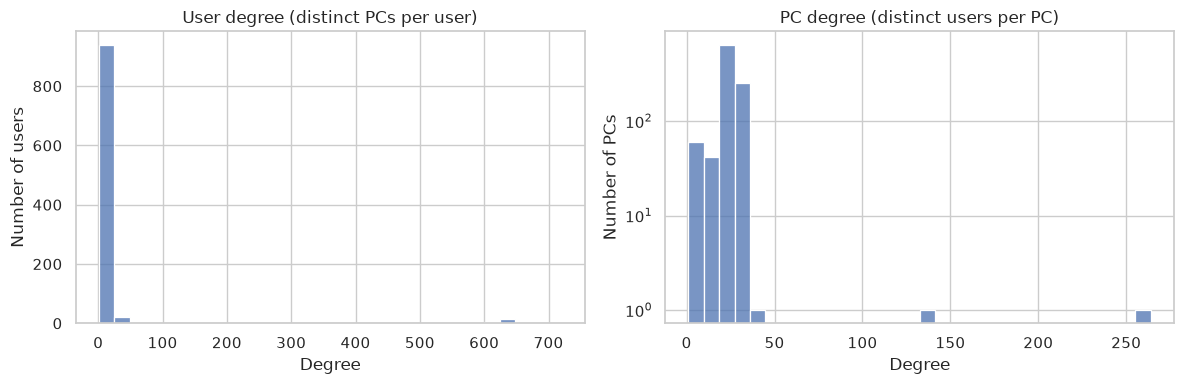

,count,mean,std,min,25%,50%,75%,max
malicious,,,,,,,,
False,930.000,20.380,102.896,1.000,1.000,1.000,2.000,720.000
True,70.000,75.971,167.922,1.000,1.000,1.000,3.000,598.000


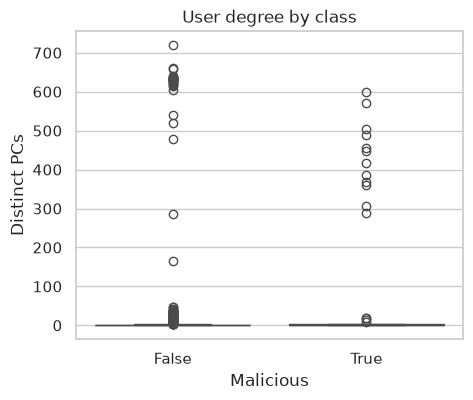

In [11]:
data, g_users, g_pcs = build_graph(logon, device, file, labels, all_users)
nu, npc = len(g_users), len(g_pcs)
n_edges = data.edge_index.shape[1] // 2  # stored in both directions
deg = np.bincount(data.edge_index[0].numpy(), minlength=nu + npc)
udeg, pdeg = deg[:nu], deg[nu:]
print(f"user nodes: {nu} | PC nodes: {npc} | undirected edges: {n_edges}")
print(f"bipartite density: {n_edges / (nu * npc):.4f}")
display(pd.DataFrame({"user degree": pd.Series(udeg).describe(), "PC degree": pd.Series(pdeg).describe()}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(udeg, bins=30, ax=axes[0]); axes[0].set(title="User degree (distinct PCs per user)", xlabel="Degree", ylabel="Number of users")
sns.histplot(pdeg, bins=30, ax=axes[1]); axes[1].set(title="PC degree (distinct users per PC)", xlabel="Degree", ylabel="Number of PCs", yscale="log")
plt.tight_layout(); plt.show()
ymal = data.y[:nu].numpy().astype(bool)
dd = pd.DataFrame({"degree": udeg, "malicious": ymal})
display(dd.groupby("malicious")["degree"].describe())
fig, ax = plt.subplots(figsize=(5, 4))
sns.boxplot(data=dd, x="malicious", y="degree", hue="malicious", palette={False: "#4c72b0", True: "#c44e52"}, legend=False, ax=ax)
ax.set(title="User degree by class", xlabel="Malicious", ylabel="Distinct PCs")
plt.show()

## 8. The split

Users are split into train/validation/test with a stratified split (`make_split`), and the same split is reused for the baseline and the GNN. We check the sizes, and how many malicious users each part holds, because the test score is only as trustworthy as the number of positives behind it.

,users,malicious,malicious %
train,550,39,7.091
val,150,10,6.667
test,300,21,7.000


config n_users: None -> users used: 1000


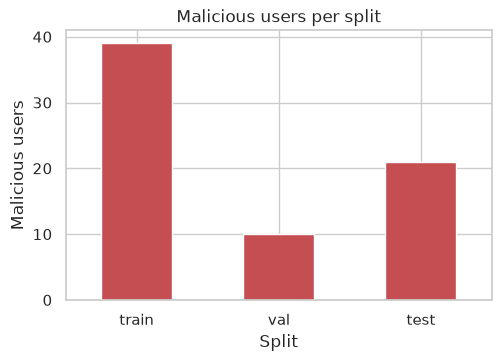

The test set holds only 21 malicious users, so one more or fewer detected moves recall by 5 points.


In [12]:
users = subsample_users(all_users, labels, cfg["n_users"], cfg["seed"])
split = make_split(users, labels, cfg["val_size"], cfg["test_size"], cfg["seed"])
sp = pd.DataFrame({k: {"users": len(v), "malicious": sum(u in labels for u in v)} for k, v in split.items()}).T
sp["malicious %"] = sp["malicious"] / sp["users"] * 100
display(sp)
print("config n_users:", cfg["n_users"], "-> users used:", len(users))
fig, ax = plt.subplots(figsize=(5.5, 3.5))
sp[["malicious"]].plot.bar(ax=ax, legend=False, color="#c44e52", rot=0)
ax.set(title="Malicious users per split", xlabel="Split", ylabel="Malicious users")
plt.show()
print(f"The test set holds only {sp.loc['test','malicious']} malicious users, so one more or fewer detected moves recall by {100/sp.loc['test','malicious']:.0f} points.")

## 9. Other files available but not used yet

`psychometric.csv` (personality scores) and the LDAP monthly snapshots (role, department, supervisor) could become extra features later. A quick look at their shape and first rows.

In [13]:
psy = pd.read_csv(RAW / "psychometric.csv")
print("psychometric.csv shape:", psy.shape); display(psy.head())
ldap_files = sorted(glob.glob(str(RAW / "LDAP" / "*.csv")))
print("LDAP files:", len(ldap_files), "|", Path(ldap_files[0]).name, "to", Path(ldap_files[-1]).name)
ldap = pd.read_csv(ldap_files[0])
print("first LDAP file shape:", ldap.shape); display(ldap.head())

psychometric.csv shape: (1000, 7)


,employee_name,user_id,O,C,E,A,N
0,Calvin Edan Love,CEL0561,40,39,36,19,40
1,Christine Reagan Deleon,CRD0624,26,22,17,39,32
2,Jade Felicia Caldwell,JFC0557,22,16,23,40,33
3,Aquila Stewart Dejesus,ASD0577,40,48,36,14,37
4,Micah Abdul Rojas,MAR0955,36,44,23,44,25


LDAP files: 18 | 2009-12.csv to 2011-05.csv
first LDAP file shape: (1000, 9)


,employee_name,user_id,email,role,business_unit,functional_unit,department,team,supervisor
0,Calvin Edan Love,CEL0561,Calvin.Edan.Love@dtaa.com,ComputerProgrammer,1,2 - ResearchAndEngineering,2 - SoftwareManagement,3 - Software,Stephanie Briar Harrington
1,Christine Reagan Deleon,CRD0624,Christine.Reagan.Deleon@dtaa.com,Salesman,1,5 - SalesAndMarketing,2 - Sales,3 - RegionalSales,Winter Veda Burks
2,Jade Felicia Caldwell,JFC0557,Jade.Felicia.Caldwell@dtaa.com,SoftwareEngineer,1,2 - ResearchAndEngineering,2 - SoftwareManagement,3 - Software,Stephanie Briar Harrington
3,Aquila Stewart Dejesus,ASD0577,Aquila.Stewart.Dejesus@dtaa.com,ProductionLineWorker,1,3 - Manufacturing,3 - Assembly,3 - AssemblyDept,Whilemina Pandora England
4,Micah Abdul Rojas,MAR0955,Micah.Abdul.Rojas@dtaa.com,ProductionLineWorker,1,3 - Manufacturing,3 - Assembly,6 - AssemblyDept,Sandra Beverly Diaz


## Key takeaways

- **Size and quality:** 1,000 users and ~1,000 PCs; logon has 854,859 rows, device 405,380, file 445,581, from 2010-01-02 to 2011-05-17. No missing values and no duplicate event ids in any log. The 6,463 (file) and 6 (device) identical rows seen on the slimmed columns are not true duplicates: with the id restored, 0 rows are fully identical. For file, 0 rows repeat (date, user, pc, filename), so they are different files in the same second. For device, 6 rows repeat (date, user, pc, activity) with different ids: possible genuine repeats, too few to matter, and the features do not dedupe them.
- **Coverage is uneven:** all 1,000 users log on, but only 265 have device events and 264 file events (264 in all three logs). Most users have zeros for `n_device` and `n_file`.
- **Label:** 70 malicious users (7.0%) from scenarios 1 (30), 2 (30) and 3 (10). Predicting "normal" for everyone is 93% accurate and finds no insiders, so use PR-AUC, precision and recall.
- **Signal:** every malicious user has device activity vs ~21% of normal users, and 60% have after-hours logons vs ~16%. The medians show the same (`n_device` 63 vs 0, `n_file` 85.5 vs 0). Linear correlations with the label are weak (|r| <= 0.13), so the signal is in presence/absence and tails rather than a smooth trend; tree models and thresholds on these features should do better than linear ones.
- **Heavy tails:** counts span orders of magnitude (e.g. `n_pcs` max 720 vs median 1, a few power users/admins), so log or symlog scales are needed; `build_graph` already applies `log1p`.
- **Graph:** 1,000 user nodes, 1,003 PC nodes, 24,271 edges, density about 2.4%. Most users touch 1-2 PCs, but a few touch hundreds; PCs have degree about 25. Malicious users have a higher mean degree (76 vs 20) but the same median (1), so degree alone does not separate the classes.
- **Split:** 550 / 150 / 300 users with 39 / 10 / 21 malicious. The test set has only 21 positives, so each insider is about 5 points of recall: expect noisy test metrics and compare models on identical splits, ideally across several seeds.
- **Unused data:** psychometric (1,000 x 7) and 18 monthly LDAP snapshots (role, department, supervisor) are available as future features.